In [1]:
from itertools import product
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from scipy.linalg import qr, svd, hankel
from tqdm import tqdm

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [2]:
np.random.seed(0)

In [3]:
def generate_data(
    n_timepoints: int, 
    n_components: int, 
    noise: int, 
    n_pixels: int, # n_pixels PER component
    n_pixels_bg
):
    interp_factor = 2
    
    clean = np.zeros((n_components, n_timepoints * interp_factor))
    
    x = 0
    a = 0.7
    
    b = 0
    
    firing_prop = 0.05
    
    spikes = list()
    
    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))
    
    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (50 * spikes[c_ix][i])
    
        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])
    
    n_timepoints *= 2
        
    series = list()
    
    for i in range(n_components):
        for j in range(n_pixels):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
    
    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])

    return series

In [4]:
movie = np.zeros((2_000, 9, 2))

In [5]:
data = generate_data(
    n_timepoints=1_000,
    n_components=2,
    noise=0,
    n_pixels=1,
    n_pixels_bg=0
)

In [6]:
data.shape

(2, 2000)

In [7]:
movie.shape

(2000, 9, 2)

In [8]:
movie[:, :, 0].shape

(2000, 9)

In [39]:
movie[:, 0:3] = data[0, None, None].T
movie[:, 3:6] = data[1, None, None].T / 2
movie[:, 6:] = data[0, None, None].T + (data[1, None, None].T / 2)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
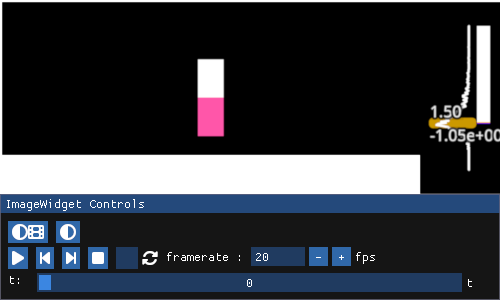

In [40]:
iw = fpl.ImageWidget(movie, cmap="gnuplot2")
iw.show()

In [41]:
t, xdim, ydim = movie.shape

In [42]:
series = movie.reshape(t, xdim * ydim).T

In [109]:
series += np.vstack([np.random.normal(scale=5, size=2_000) for i in range(18)])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
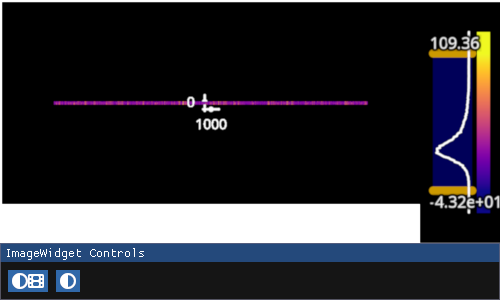

In [110]:
iw_series = fpl.ImageWidget(series)
iw_series.show()

In [111]:
class SpaceTimeSVD:
    def __init__(self, movie_vectorized: np.ndarray, w: int):
        self.movie = movie_vectorized
        self.w = w
        self.adjacency = None

    def compute(self):
        print("Computing F, P")
        Ys = list()
        Ps = list()
        Fs = list()

        series = self.movie
        w = self.w

        n_pixels = self.movie.shape[0]
        for i in tqdm(range(n_pixels)):
            y = hankel(series[i, :w], series[i, w:])
            p = np.flipud(y[:int(w / 2)])
            f = y[int(w / 2):]
        
            Ys.append(y)
            Ps.append(p)
            Fs.append(f)

        P_F_shape = (int(w / 2) * n_pixels, series.shape[1] - w)
        print(movie.shape)
        print(P_F_shape)

        P = np.zeros(P_F_shape)
        F = np.zeros(P_F_shape)
        
        for i in tqdm(range(n_pixels)):
            P[i::n_pixels] = Ps[i]
            F[i::n_pixels] = Fs[i]

        print("computing H")
        H = (F @ P.T) / P.shape[1]

        print("Computing Hp")
        Hp = np.zeros((int(w / 2)**2, n_pixels**2))

        for row_ix, (block_i, block_j) in enumerate(product(*[range(0, int(w / 2) * n_pixels, n_pixels)]*2)):
            Hp[row_ix] = H.T[block_i:block_i + n_pixels, block_j:block_j + n_pixels].ravel()

        del H

        print("computimng svd of Hp")
        u, s, v = svd(Hp)

        del Hp

        self.adjacency = v[0].reshape(self.movie.shape[0], self.movie.shape[0])

In [112]:
class ClusteringCPQR:
    def __init__(self, adjacency: np.ndarray, k: int):
        self.k = k
        self.B = np.abs(adjacency + adjacency.T) / 2
        self.evals, self.evecs = np.linalg.eigh(self.B)

        self.vk = self.evecs[:, -self.k:]

        self.vkT = self.vk.T
        self.vkT /= np.linalg.norm(self.vkT, axis=0, ord=2)

        Q, R, self.pivots = qr(self.vkT, pivoting=True)
        
        u, s, vT = np.linalg.svd(self.vkT[:, self.pivots[:self.k]], full_matrices=False)
        self.U = u @ vT

        self.transformed = self.U.T @ self.vkT

        self.labels = self.transformed.argmax(axis=0)

In [199]:
clustering.vkT.shape

(2, 18)

In [200]:
np.linalg.norm(clustering.vkT, axis=0, ord=2)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1.])

In [113]:
st_svd = SpaceTimeSVD(series, w=16)
st_svd.compute()

Computing F, P


100%|████████████████████████████████████████████████████████████████████████████████████████| 18/18 [00:00<00:00, 20404.72it/s]


(2000, 9, 2)
(144, 1984)


100%|████████████████████████████████████████████████████████████████████████████████████████| 18/18 [00:00<00:00, 10710.38it/s]

computing H
Computing Hp
computimng svd of Hp


RFBOutputContext()

JupyterWgpuCanvas()
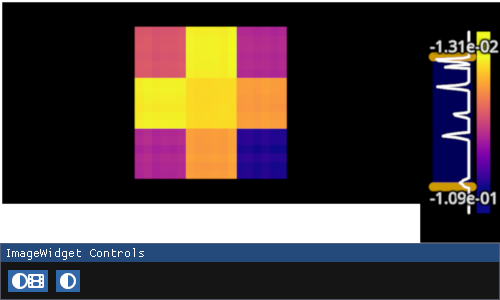

In [114]:
iw_adj = fpl.ImageWidget(st_svd.adjacency)
iw_adj.show()

In [137]:
st_svd.adjacency

array([[-0.05597278, -0.05557442, -0.05742713, -0.05644162, -0.05697133,
        -0.05580623, -0.01498523, -0.01579264, -0.01556652, -0.01540376,
        -0.01631572, -0.01384161, -0.07119438, -0.0709504 , -0.07236686,
        -0.0714417 , -0.07269086, -0.07167031],
       [-0.05501923, -0.05438045, -0.05639721, -0.05549326, -0.05607794,
        -0.05480015, -0.01425193, -0.01494651, -0.0147642 , -0.01454801,
        -0.01567425, -0.01319925, -0.069497  , -0.06939285, -0.07070138,
        -0.06980174, -0.07122216, -0.07003728],
       [-0.05490056, -0.0544778 , -0.05652679, -0.05530749, -0.05583738,
        -0.05481071, -0.01417981, -0.01476033, -0.01459756, -0.01453243,
        -0.01552259, -0.01312099, -0.06937611, -0.06904436, -0.0701086 ,
        -0.06947561, -0.07066092, -0.0697289 ],
       [-0.0559179 , -0.05534442, -0.05737966, -0.05629969, -0.05681148,
        -0.05569757, -0.01444004, -0.01511223, -0.01494693, -0.01453888,
        -0.01586734, -0.01335224, -0.0706929 , -0.070

best: k = n_components + 1

1) few bg pixels, real components cluster compactly, bg points are scattered
2) lots of bg pixels, bg points compact, real components less compact

In [115]:
clustering = ClusteringCPQR(st_svd.adjacency, k=2)

In [116]:
clustering.vkT.shape

(2, 18)

In [117]:
clustering.U.shape

(2, 2)

In [118]:
clustering.transformed.shape

(2, 18)

In [119]:
import pygfx
from wgpu.gui.jupyter import WgpuCanvas

canvas = WgpuCanvas()
renderer = pygfx.WgpuRenderer(target=canvas, blend_mode="weighted_plus")

fig = fpl.Figure(
    cameras="3d", 
    controller_types="orbit", 
    size=(1000, 800),
    renderer=renderer,
    canvas=canvas
)

subplot = fig[0, 0]

subplot.add_scatter(clustering.vkT.T, colors="r", name="vk.T", sizes=15, alpha=0.2)
subplot.add_scatter(clustering.U.T, colors="b", name="U", sizes=15, alpha=0.2)
subplot.add_scatter(clustering.transformed.T, colors="g", name="transform", sizes=15, alpha=0.2)


fig[0, 0].axes.intersection = (0, 0, 0)
fig.canvas.quality = 100
fig.show(sidecar=True)

RFBOutputContext()

/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:264: RuntimeWarning: divide by zero encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:264: RuntimeWarning: invalid value encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:276: RuntimeWarning: invalid value encountered in divide
  screen_sel = (ndc_sel[:, :2] / ndc_sel[:, 3:4]) * half_canvas_size


In [120]:
from fastplotlib.graphics._axes import Axes

In [121]:
if clustering.k == 2:
    basis_U = np.array([
        [*clustering.U.T[0], 0],
        [*clustering.U.T[1], 0],
        [0., 0., 1.]
    ])

elif clustering.k == 3:
    basis_U = np.array([
        clustering.U.T[0],
        clustering.U.T[1],
        clustering.U.T[2]
    ])

axes_U = Axes(fig[0, 0], intersection=(0, 0, 0), basis=basis_U)
axes_U.colors = ("b", "b", "b")

fig[0, 0].scene.add(axes_U.world_object)
fig[0, 0].add_animations(axes_U.update_using_camera)

fig[0, 0].axes.colors = ("g", "g", "g")

In [122]:
from ipywidgets import IntSlider, Button, VBox

In [123]:
clustering.transformed.argmax(axis=0)

array([0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [124]:
slider_n_components = IntSlider(min=2, max=50, step=1, description="n_components")
slider_n_pixels = IntSlider(min=1, max=15, step=1, description="pixels per component")
slider_noise = IntSlider(min=0, max=30, step=1, description="noise sigma")
slider_n_bg_pixels = IntSlider(min=0, max=100, step=1, description="n background pixels")
slider_k = IntSlider(min=2, max=50, step=1, description="k")
button = Button(description="Update")

iw_movie = fpl.ImageWidget(series, figure_kwargs={"size": (1200, 600)})
iw_movie.figure.show(maintain_aspect=False)

iw = fpl.ImageWidget(
    [clustering.vkT.T, clustering.U, clustering.transformed.T], 
    names=["vk.T", "U", "transform"], 
    figure_shape=(1, 3),
    figure_kwargs={"controller_ids": [[0, 1, 2]], "size": (1200, 350)},
)
iw.cmap = ["bwr", "bwr", "viridis"]
iw.figure.show(maintain_aspect=False)

thres_labels = (clustering.transformed.T > 0.2).astype(int)

cluster_labels0 = iw_movie.figure[0, 0].add_line(np.column_stack([np.zeros(series.shape[0]), np.arange(series.shape[0])]), cmap="tab10", cmap_transform=thres_labels[:, 0], thickness=8, offset=(-30, 0, 0))
cluster_labels1 = iw_movie.figure[0, 0].add_line(np.column_stack([np.zeros(series.shape[0]), np.arange(series.shape[0])]), cmap="tab10", cmap_transform=thres_labels[:, 1], thickness=8, offset=(-10, 0, 0))

def update_movie(*args):
    movie = generate_data(
        n_timepoints=1_000, 
        n_components=slider_n_components.value,
        noise=slider_noise.value,
        n_pixels=slider_n_pixels.value,
        n_pixels_bg=slider_n_bg_pixels.value,
    )

    global st_svd
    
    st_svd = SpaceTimeSVD(movie, w=16)
    st_svd.compute()

    iw_movie.set_data(movie)
    iw_movie.figure[0, 0].auto_scale(maintain_aspect=False)

def update_clustering(*args):
    global st_svd
    
    clustering = ClusteringCPQR(st_svd.adjacency, k=slider_k.value)

    iw.set_data([clustering.vkT, clustering.U, clustering.transformed])
    
    for subplot in iw.figure:
        subplot.auto_scale(maintain_aspect=False)

    iw.cmap = ["bwr", "bwr", "viridis"]

sliders = VBox([slider_n_components, slider_n_pixels, slider_noise, slider_n_bg_pixels, button])

button.on_click(update_movie)

button_clustering = Button(description="Update k")
button_clustering.on_click(update_clustering)

VBox([sliders, iw_movie.show(), slider_k, button_clustering, iw.show()])

RFBOutputContext()

RFBOutputContext()

In [125]:
clustering.vkT.T

array([[-0.71454077, -0.6995938 ],
       [-0.7467212 , -0.66513716],
       [-0.74604971, -0.66589025],
       [-0.74695616, -0.66487329],
       [-0.74082053, -0.67170302],
       [-0.72400689, -0.68979274],
       [ 0.95479022, -0.29728039],
       [ 0.95478633, -0.29729288],
       [ 0.95270369, -0.30390077],
       [ 0.94914976, -0.31482492],
       [ 0.94856566, -0.31658046],
       [ 0.95790499, -0.28708541],
       [ 0.20138736, -0.97951168],
       [ 0.23025218, -0.97313099],
       [ 0.20750693, -0.97823355],
       [ 0.16111076, -0.98693633],
       [ 0.2192706 , -0.97566408],
       [ 0.21532517, -0.97654241]])

In [138]:
clustering.vkT.T.shape

(18, 2)

In [141]:
clustering.vkT.T[:6]

clustering.vkT.T[6:12]

array([[-0.47426102, -0.4742495 , -0.46813853, -0.45795664, -0.4563111 ,
        -0.48361899],
       [-0.51522987, -0.51521865, -0.50926835, -0.4993485 , -0.49774466,
        -0.52433679],
       [-0.51436486, -0.51435364, -0.50839975, -0.49847406, -0.49686929,
        -0.52347736],
       [-0.51553265, -0.51552143, -0.50957238, -0.49965458, -0.49805107,
        -0.5246376 ],
       [-0.50764407, -0.50763279, -0.50165139, -0.49168078, -0.49006886,
        -0.51679954],
       [-0.48621284, -0.48620141, -0.48013549, -0.47002702, -0.46839316,
        -0.49550037]])

In [142]:
a = clustering.vkT.T[0]

b = clustering.vkT.T[10]

c = clustering.vkT.T[-1]

np.column_stack([a.T, b.T, c.T])

array([[-0.71454077,  0.94856566,  0.21532517],
       [-0.6995938 , -0.31658046, -0.97654241]])

In [143]:
a = np.column_stack([a.T, b.T])
np.linalg.solve(a, c)

array([0.96440466, 0.95347286])

In [145]:
import scipy

In [150]:
vk = clustering.vkT.T
idx, proj = scipy.linalg.interpolative.interp_decomp(vk.T, eps_or_k=2)

In [157]:
vk

array([[-0.71454077, -0.6995938 ],
       [-0.7467212 , -0.66513716],
       [-0.74604971, -0.66589025],
       [-0.74695616, -0.66487329],
       [-0.74082053, -0.67170302],
       [-0.72400689, -0.68979274],
       [ 0.95479022, -0.29728039],
       [ 0.95478633, -0.29729288],
       [ 0.95270369, -0.30390077],
       [ 0.94914976, -0.31482492],
       [ 0.94856566, -0.31658046],
       [ 0.95790499, -0.28708541],
       [ 0.20138736, -0.97951168],
       [ 0.23025218, -0.97313099],
       [ 0.20750693, -0.97823355],
       [ 0.16111076, -0.98693633],
       [ 0.2192706 , -0.97566408],
       [ 0.21532517, -0.97654241]])

In [156]:
idx

array([ 4, 13,  2,  3,  0,  5,  6,  7,  8,  9, 10, 11, 12,  1, 14, 15, 16,
       17], dtype=int32)

In [166]:
proj.shape

(2, 16)

In [168]:
np.round(proj)

array([[ 1.,  1.,  1.,  1., -1., -1., -1., -1., -1., -1.,  0.,  1.,  0.,
         0.,  0.,  0.],
       [-0., -0.,  0.,  0.,  1.,  1.,  1.,  1.,  1.,  1.,  1., -0.,  1.,
         1.,  1.,  1.]])

In [172]:
proj

array([[ 1.00428321,  1.00502322,  0.97812671,  0.98607012, -0.98299406,
        -0.98298645, -0.97893407, -0.97211143, -0.97100059, -0.98913686,
         0.0337588 ,  1.00483147,  0.0266213 ,  0.0804754 ,  0.01287126,
         0.01748725],
       [-0.00892974, -0.01048557,  0.0437589 ,  0.02820429,  0.98399955,
         0.98400714,  0.98800033,  0.99451677,  0.99555403,  0.97776315,
         0.98325487, -0.01008206,  0.9868681 ,  0.95863842,  0.99371865,
         0.99143504]])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
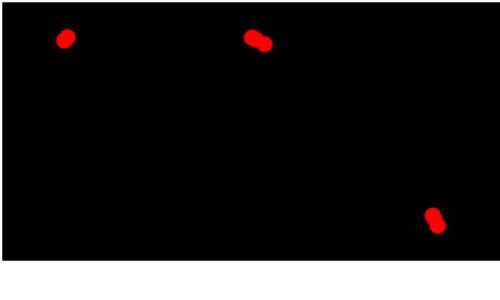

In [174]:
fig_proj = fpl.Figure()
fig_proj[0, 0].add_scatter(proj.T, sizes=15, colors="r")
fig_proj.show()

In [177]:
rounded_proj = np.round(proj)
rounded_proj.T

array([[ 1., -0.],
       [ 1., -0.],
       [ 1.,  0.],
       [ 1.,  0.],
       [-1.,  1.],
       [-1.,  1.],
       [-1.,  1.],
       [-1.,  1.],
       [-1.,  1.],
       [-1.,  1.],
       [ 0.,  1.],
       [ 1., -0.],
       [ 0.,  1.],
       [ 0.,  1.],
       [ 0.,  1.],
       [ 0.,  1.]])

In [193]:
basis = np.unique(rounded_proj.T, axis=0)

In [194]:
basis

array([[-1.,  1.],
       [ 0.,  1.],
       [ 1., -0.]])

In [195]:
basis[0] = basis[0] + basis[-1]
basis

array([[ 0.,  1.],
       [ 0.,  1.],
       [ 1., -0.]])

In [196]:
basis[1] = basis[1] + basis[-1]

In [197]:
basis

array([[ 0.,  1.],
       [ 1.,  1.],
       [ 1., -0.]])

In [175]:
fig_proj[0, 0].axes.intersection = (0, 0, 0)

In [126]:
clustering.pivots

array([ 2, 13,  0,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12,  1, 14, 15, 16,
       17], dtype=int32)

In [127]:
clustering.U

array([[-0.88675854,  0.46223294],
       [-0.46223294, -0.88675854]])

In [128]:
clustering.transformed.T

array([[ 0.95700043,  0.2900865 ],
       [ 0.96960971,  0.24465692],
       [ 0.96936236,  0.24563511],
       [ 0.96969609,  0.24431433],
       [ 0.96741219,  0.25320673],
       [ 0.96086422,  0.27701977],
       [-0.7092556 ,  0.70495142],
       [-0.70924637,  0.7049607 ],
       [-0.70434518,  0.70985763],
       [-0.69614421,  0.71790197],
       [-0.69481478,  0.71918872],
       [-0.71673009,  0.69735068],
       [ 0.2741806 ,  0.96167822],
       [ 0.24563511,  0.96936236],
       [ 0.26816323,  0.96337349],
       [ 0.31332814,  0.94964492],
       [ 0.25654401,  0.96653255],
       [ 0.26044864,  0.9654877 ]])

In [129]:
thres_labels

array([[1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1]])

In [130]:
clustering.U

array([[-0.88675854,  0.46223294],
       [-0.46223294, -0.88675854]])

In [131]:
clustering.transformed

array([[ 0.95700043,  0.96960971,  0.96936236,  0.96969609,  0.96741219,
         0.96086422, -0.7092556 , -0.70924637, -0.70434518, -0.69614421,
        -0.69481478, -0.71673009,  0.2741806 ,  0.24563511,  0.26816323,
         0.31332814,  0.25654401,  0.26044864],
       [ 0.2900865 ,  0.24465692,  0.24563511,  0.24431433,  0.25320673,
         0.27701977,  0.70495142,  0.7049607 ,  0.70985763,  0.71790197,
         0.71918872,  0.69735068,  0.96167822,  0.96936236,  0.96337349,
         0.94964492,  0.96653255,  0.9654877 ]])

In [132]:
thres_labels = (clustering.transformed.T > 0.2).astype(int)
thres_labels

array([[1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1]])

In [133]:
cluster_labels.cmap = "tab10"

In [134]:
selector_movie = iw_movie.managed_graphics[0].add_linear_selector(axis="y")
selector_vkT = iw.figure["vk.T"]["image_widget_managed"].add_linear_selector(axis="y")
selector_transform = iw.figure["transform"]["image_widget_managed"].add_linear_selector(axis="y")
selectors = [selector_movie, selector_vkT, selector_transform]

In [135]:
class IndexStore:
    def __init__(self):
        self.index: int = None

    def set_index(self, new_index: int, source_graphic: fpl.LinearSelector | fpl.ScatterGraphic):
        self._set_points(new_index)
        self._set_linear_selectors(new_index, source_graphic)

    def _set_points(self, index: int):
        # reset colors
        subplot["vk.T"].colors = (1, 0, 0, 0.2)
        subplot["vk.T"].sizes = 15
        
        subplot["transform"].colors = (0, 1, 0, 0.2)
        subplot["transform"].sizes = 15
        
        # set colors and size
        subplot["vk.T"].colors[index] = "yellow"
        subplot["vk.T"].sizes[index] = 25
        
        subplot["transform"].colors[index] = "cyan"
        subplot["transform"].sizes[index] = 25

    def _set_linear_selectors(self, index: int, source_graphic):
        with fpl.pause_events(*selectors):
            for selector in selectors:
                if source_graphic is selector:
                    continue
                selector.selection = index

    def _scatter_callback(self, ev):
        index = ev.pick_info["vertex_index"]
        self.set_index(index, ev.graphic)
    
    def register_scatter(self, graphic: fpl.ScatterGraphic):
        graphic.add_event_handler(self._scatter_callback, "click")

    def _linear_selector_callback(self, ev):
        index = ev.get_selected_index()
        self.set_index(index, ev.graphic)
    
    def register_linear_selector(self, selector: fpl.LinearSelector):
        selector.add_event_handler(self._linear_selector_callback, "selection")

In [136]:
index_store = IndexStore()

index_store.register_scatter(subplot["vk.T"])
index_store.register_scatter(subplot["transform"])

index_store.register_linear_selector(selector_movie)
index_store.register_linear_selector(selector_vkT)
index_store.register_linear_selector(selector_transform)